# introduction
This document presents the LDPC decoder performance simulation results. The GEObackhaul system supports a subset of the 3GPP 5G LDPC configuration with the following specifications:
- Base Graph: BG2
- Payload Sizes: [256, 320, 384, 400, 480, 512, 640, 768, 800, 960, 1280, 3840] bits (includes 24-bit CRC)
- Post-Rate Matching Code Rates: 1/4 and 1/5

## LDPC Decoder Implementation & Simulation Overview
- Decoder algorithms implementation
  - Three python-based floating point LDPC decoder:  [BP, normalized min-sum, layered min-sum]
  - Two c-based fixed point LDPC layered min-sum decoder: [16bits fixed point and 8 bits fixed point]
    - FPGA ARM R core has only L2-cache level 128KB TCM(on-chip memory), 8 bits function is optimized to occupy less than 100KB data memory to maximuze execution speed
    - 16bits function is ~0.15db better than 8 bits function and is expected to run on ARM A core by putting data memorty into DDR

- Fixed-Point Fine-Tuning

  To optimize hardware performance, the following parameters were simulated and refined:
  - Input LLRs were normalized to 4 valid bits.
  - Optimized selection of filling bit LLRs to 127/4.
  - LDPC decoder iteration size selection: 

- LDPC performance simulation
  - different algorithms
  - different LDPC configuration(code rate, payload size)
  - different SNR

## Performance Analysis & Comparison
1. Algorithm & Fixed-Point Comparison
   - Floating-Point Baselines: Simulation results show no significant performance variance between the Belief Propagation (BP), Normalized Min-Sum (NMS), and Layered Min-Sum (LMS) algorithms.
   - 16-bit Layered Min-Sum vs. Floating-Point Layered Min-Sum: The 16-bit is almost identical with the floating-point.
   - 8-bit Layered Min-Sum vs. 16-bit Layered Min-Sum: The 8-bit fixed-point LMS decoder ~0.15 dB lower than 16-bits

2. BER and BLER Relationship
   - While lower Block Error Rates (BLER) generally correspond with lower Bit Error Rates (BER), they do not share a direct mathematical correlation in LDPC decoding:
   - Under the assumption of Independent and Identically Distributed (i.i.d.) bit errors,  $BLER = 1-(1-BER)^N$
   - In practice, LDPC decoding does not produce independent bit errors. Due to the iterative nature of the algorithm, error messages propagate across the parity-check matrix, causing errors to spread among related bits
   - BLER is the most critical performance metric for LDPC decoding
     - upper layer will discard the whole packet when CRC is failed even if caused by a single error
     - BLER directly reflects the packet success rate required by upper-layer protocols


## recommendation of 8bits fixed point layered min-sum parameter
- Input LLRs were normalized to 4 valid bits.
- Optimized selection of filling bit LLRs to 127/4.
- LDPC decoder iteration size: 24 

## summary of the BLER vs SNR simulation
- ~1.1dB gain from 1/4 rate to 1/5 rate
- Payload 256 is a clear outlier, showing a 0.5 dB performance penalty relative to the other simulated payload sizes
- SNR requirements remain relatively stable for Payload from 256 to 512
- SNR requirements remain relatively stable for Payload from 640 to 1280
- payload 3840 shows a significant performance leap: ~0.3dB
  

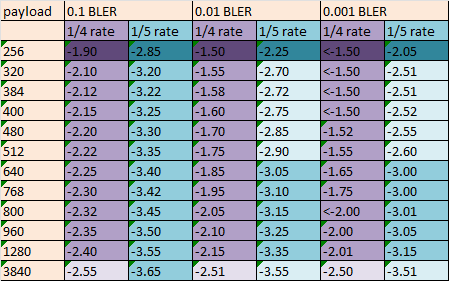

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
import seaborn as sns
import os
import pickle


## Test 1:  test three different floating point algorithms: [BP, normalized min-sum, layered min-sum]

In [116]:
import importlib
importlib.reload(utils_for_plot)
fp_df = utils_for_plot.process_floating_point_simu_result()


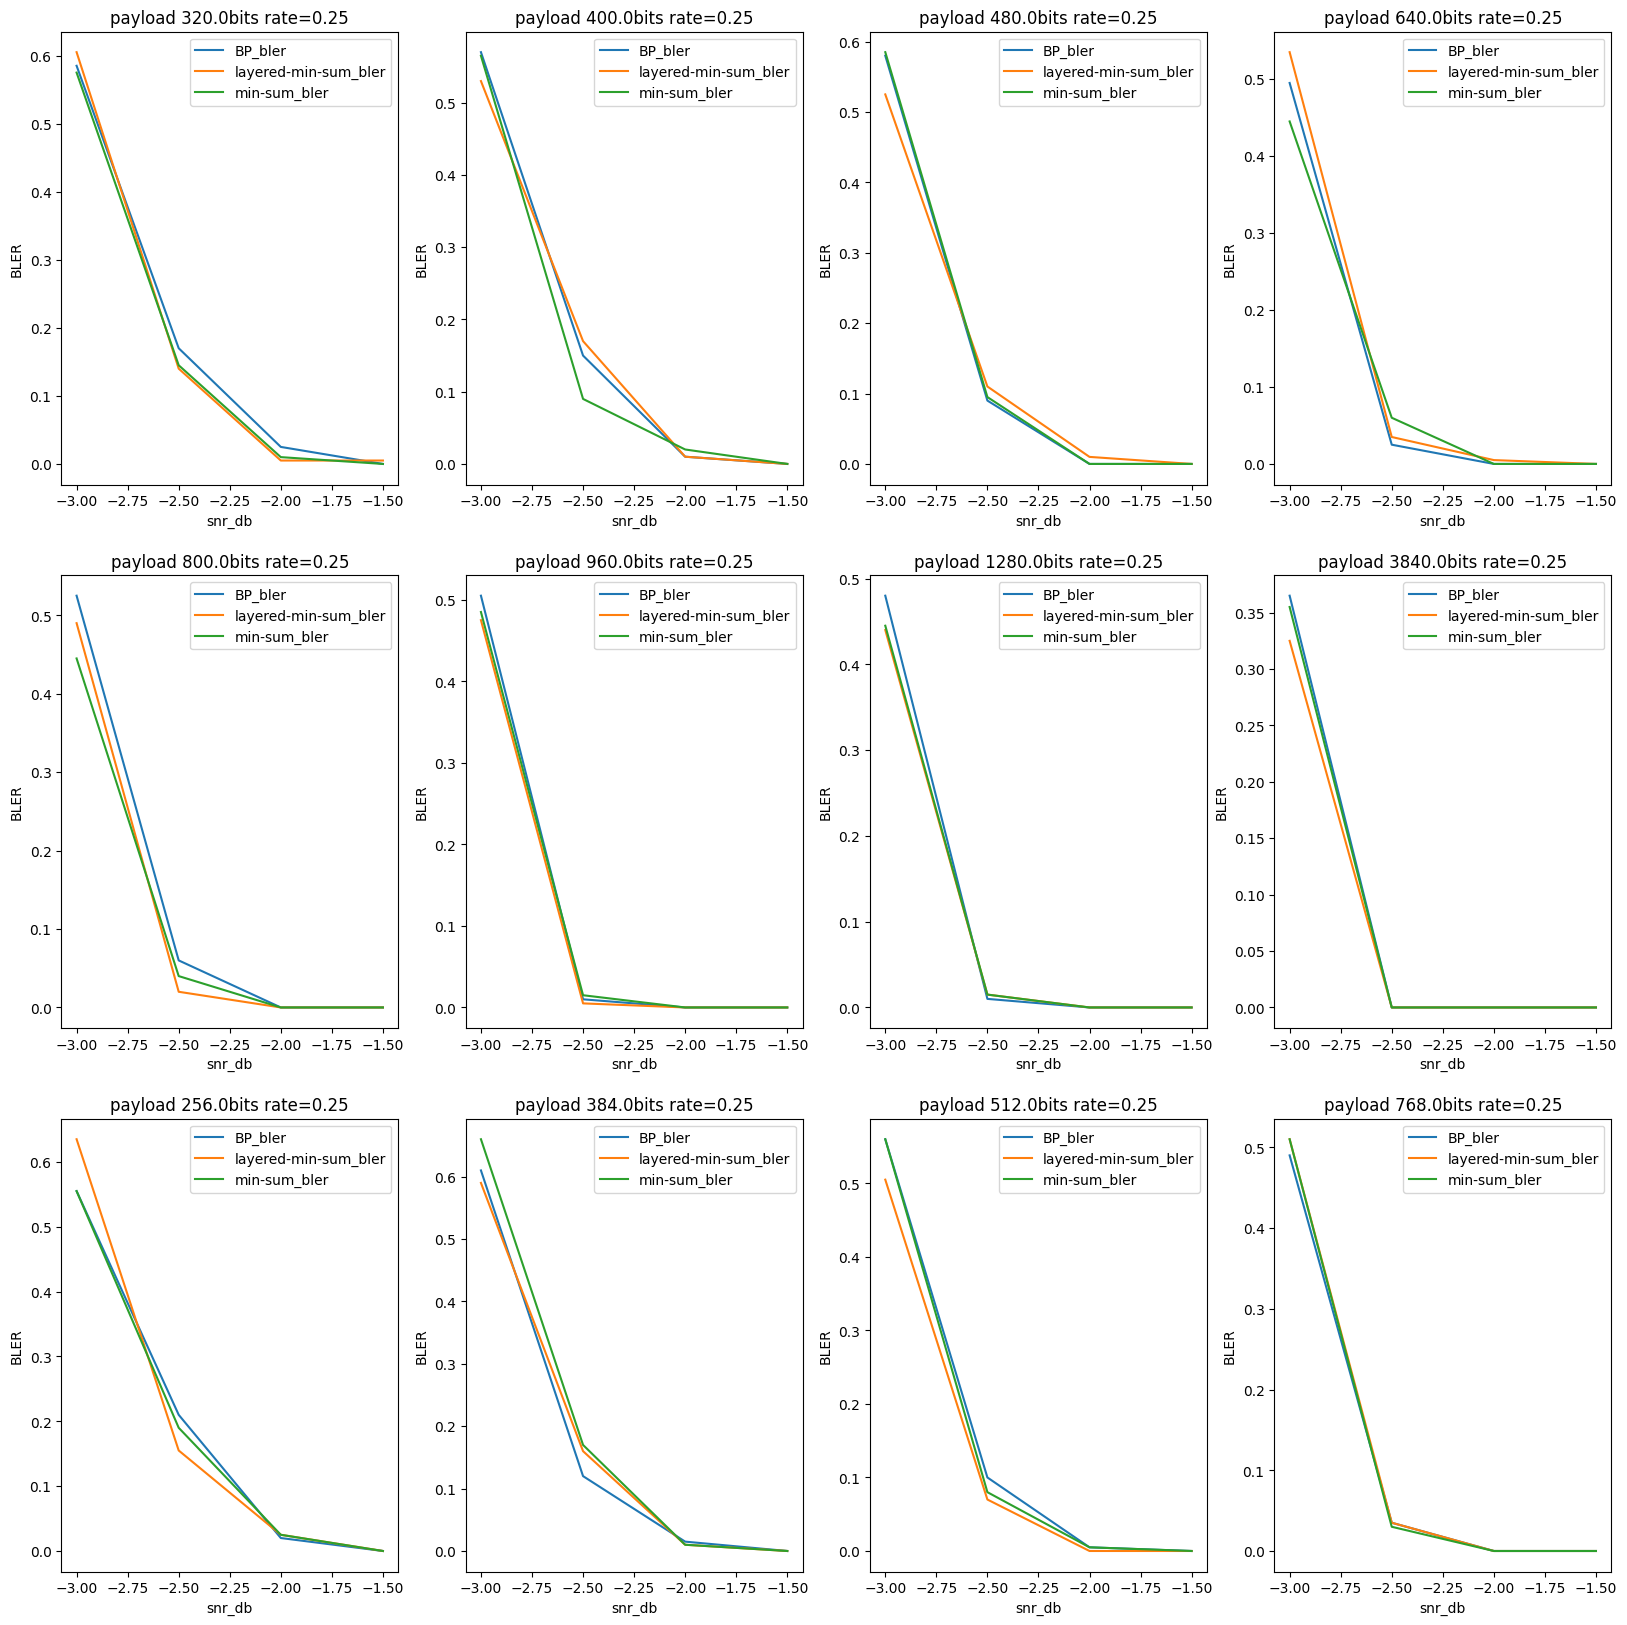

In [115]:
import matplotlib.pyplot as plt
fig,axes = plt.subplots(int(fp_df['payload_size'].unique().size//4),4,figsize=(20,20))

for idx,payload in enumerate(fp_df['payload_size'].unique()):
    sel_d = fp_df[fp_df['payload_size']==payload]
    
    for rate_idx,rate in enumerate([0.25]):
        sel_ax = axes[idx //4, (idx % 4)]
        for bler in ["BP_bler",	"layered-min-sum_bler",	"min-sum_bler"]:
            label = f"{bler}"
            sns.lineplot(data=sel_d[sel_d['datarate']==rate], x='snr_db', y=bler,ax=sel_ax,label=label,errorbar=None)
            
        sel_ax.set(title=f'payload {payload}bits rate=0.25', xlabel='snr_db', ylabel='BLER')
        #sel_ax.set_yscale('log') 
        sel_ax.legend()
    

## test 2: test floating poing layered min-sum algorithm and 16bits c-code fixed-point layered min-sum algorithm

In [2]:
#load data
import utils_for_plot
int16_df, int16_df2 = utils_for_plot.process_int16_fixed_point_simu_result()


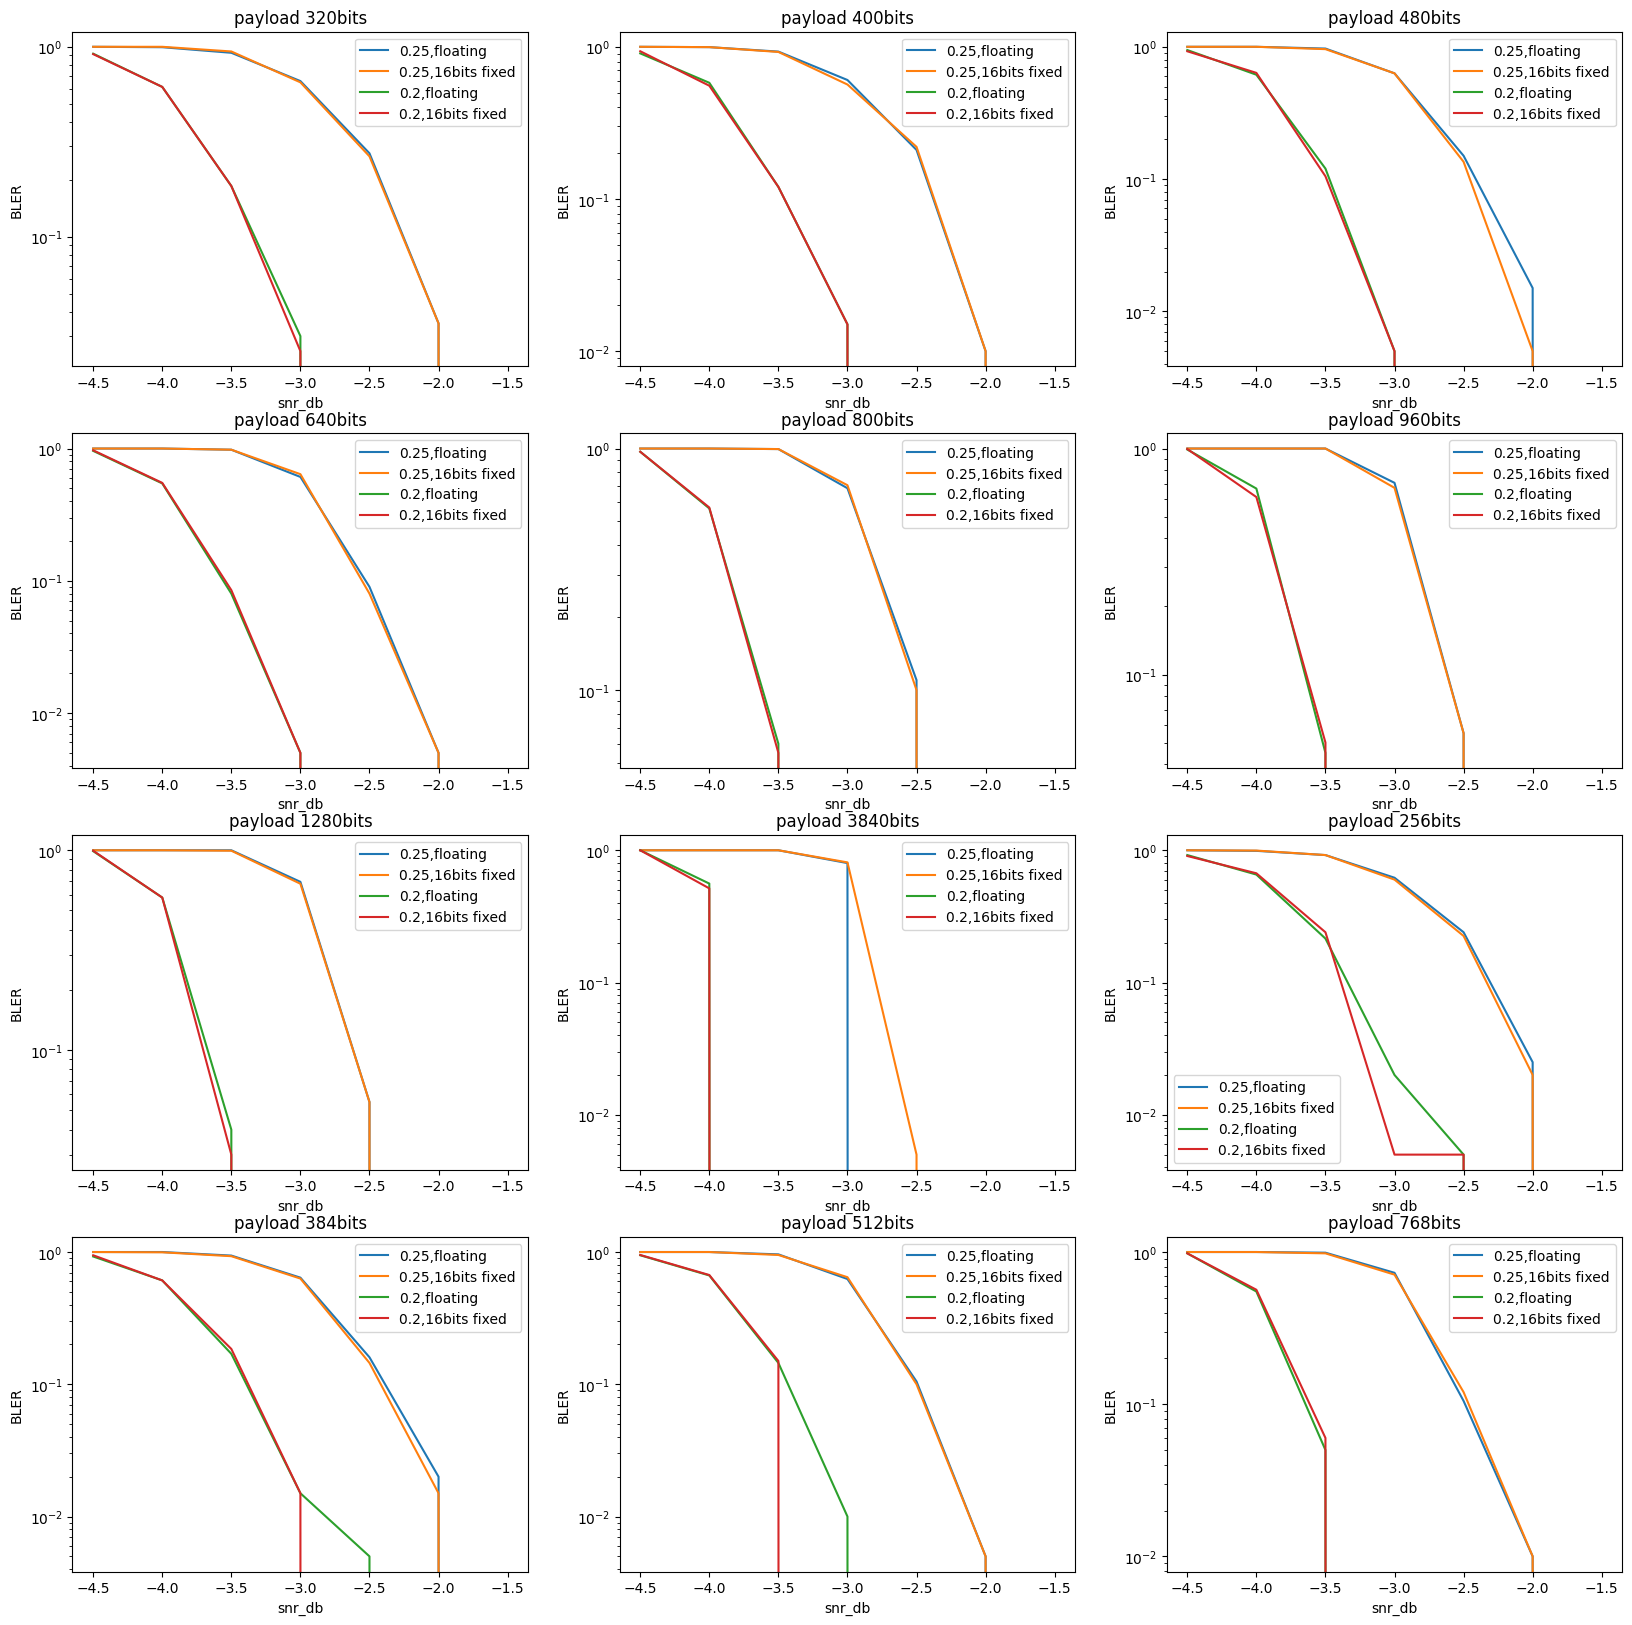

In [117]:
import matplotlib.pyplot as plt
fig,axes = plt.subplots(4,3,figsize=(20,20))

for idx,payload in enumerate(int16_df['payload'].unique()):
    sel_d = int16_df[int16_df['payload']==payload]
    for rate in int16_df['rate'].unique():
        sel_ax = axes[idx //3, idx % 3]
        label1 = f"{rate},floating"
        label2 = f"{rate},16bits fixed"
        sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y='f_BLER',ax=sel_ax,label=label1,errorbar=None)
        sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y='16bits_BLER',ax=sel_ax,label=label2,errorbar=None)
    
        sel_ax.set(title=f'payload {payload}bits', xlabel='snr_db', ylabel='BLER')
        sel_ax.set_yscale('log') 
        sel_ax.legend()
    

## test 3: int16 and int8 fixed point BLER and BER

**Summary of the test**
- it test BER and BLER for int16 and int8 fixed point c code
- 20000 tests are accumulated for each test configuratio

**Observation of the test**
- lower BLER also indicate lower BER
- But there is no direct relation between BLER and BER
 if bit error rate is i.i.d( Independent and Identically Distributed), then $BLER = 1-(1-BER)^N$
 But bit error is not independent each other for LDPC decoder. Error spread out to other bits during the iteration of LDPC decoding.

In [47]:
import importlib
importlib.reload(utils_for_plot)

ber_df, ber_df2 = utils_for_plot.process_int8_BER_fixed_point_simu_result()

In [54]:
ber_df.columns.tolist()[4:]

['8bits_BLER', '16bits_BLER', '8bits_BER', '16bits_BER']

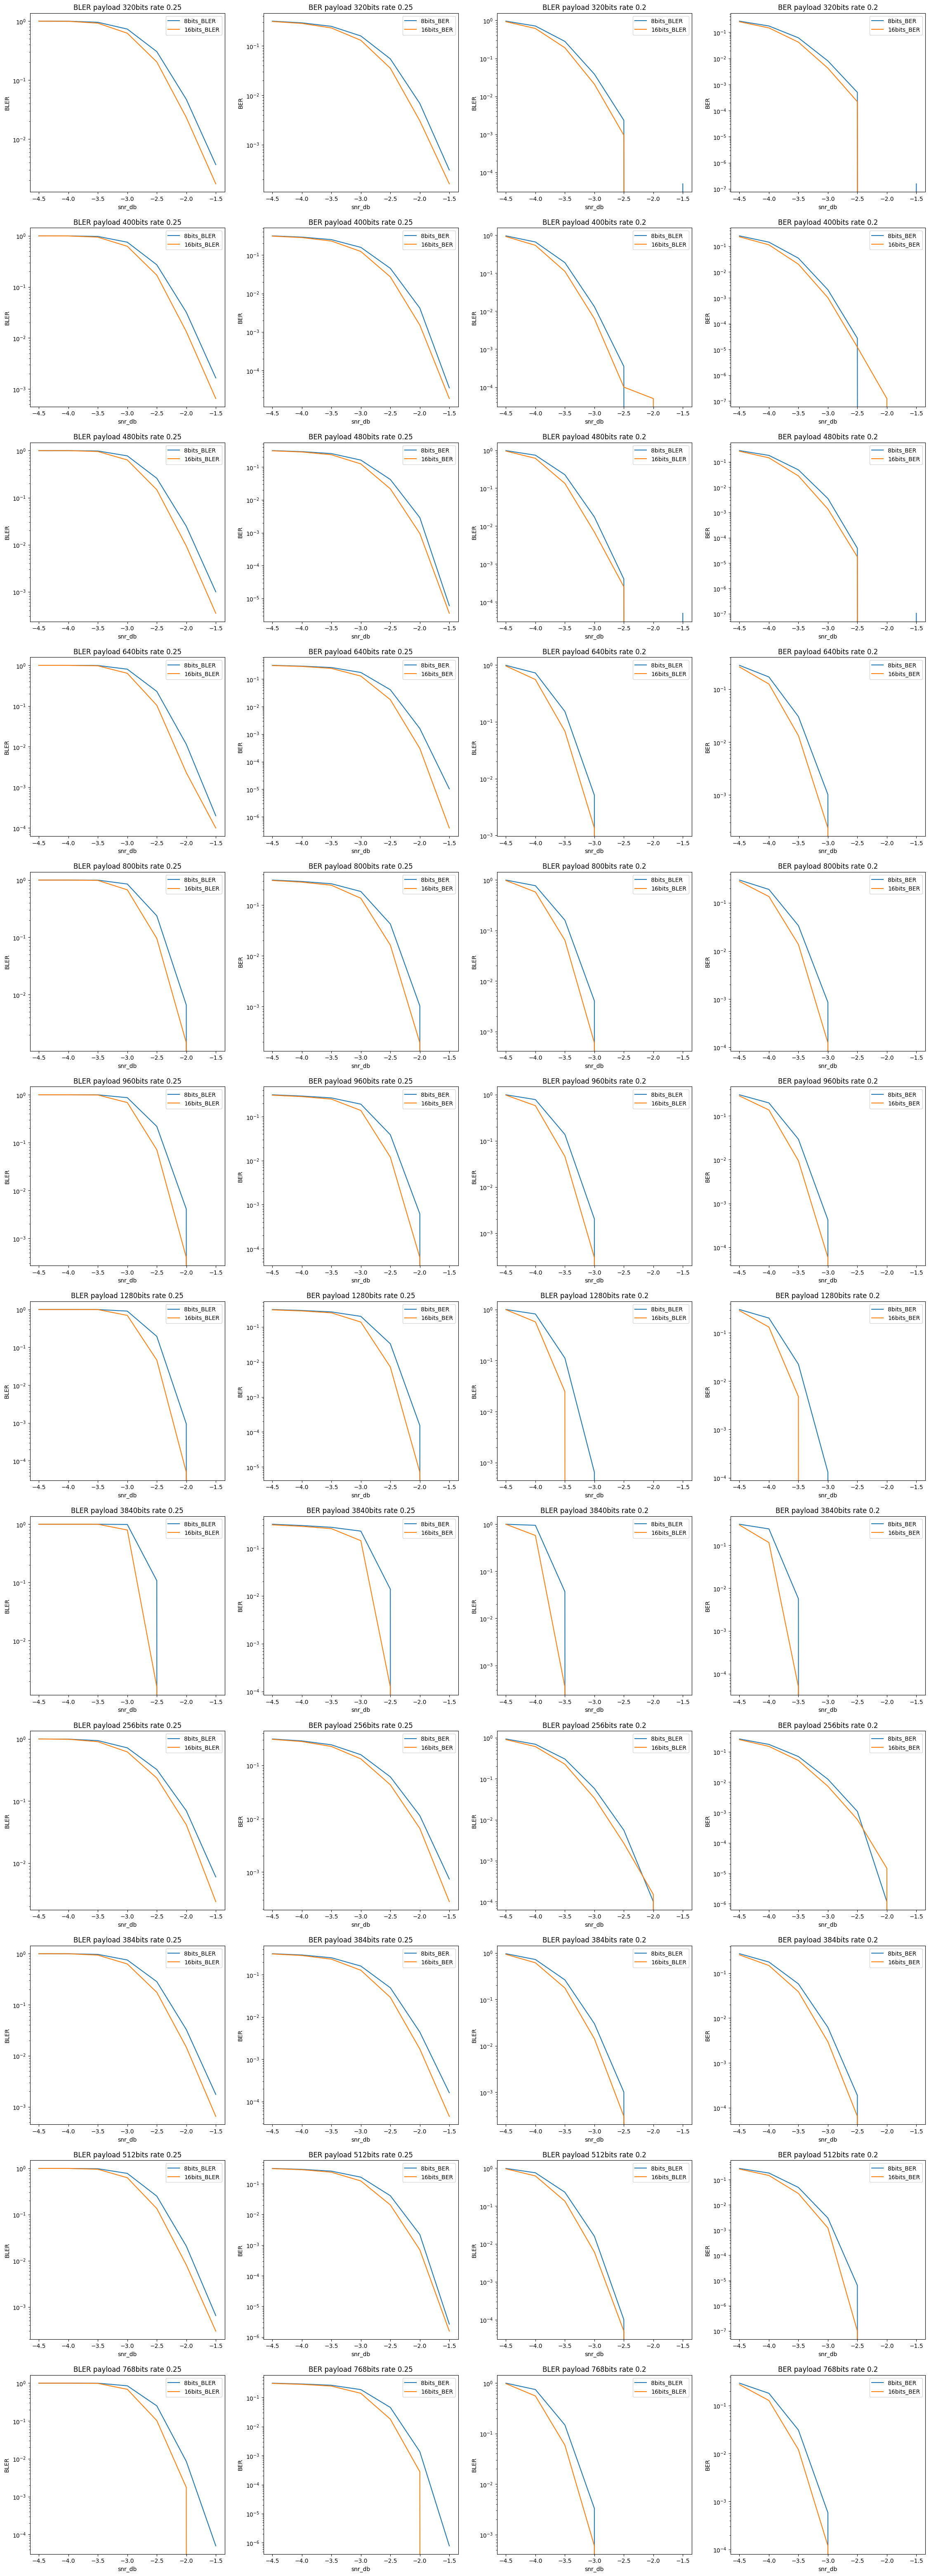

In [120]:
import matplotlib.pyplot as plt

bler_col_list=['8bits_BLER','16bits_BLER']
ber_col_list=['8bits_BER','16bits_BER']

fig,axes = plt.subplots(ber_df['payload'].unique().size, 4,figsize=(28,80))

for idx,payload in enumerate(ber_df['payload'].unique()):
    sel_d = ber_df[ber_df['payload']==payload]
    for rate_idx, rate in enumerate(ber_df['rate'].unique()):
        
        #plot BLER
        sel_ax = axes[idx, rate_idx*2]
        for col_idx, label in enumerate(bler_col_list):
            sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y=label,ax=sel_ax,label=label,errorbar=None)
        sel_ax.set(title=f'BLER payload {payload}bits rate {rate}', xlabel='snr_db', ylabel='BLER')
        sel_ax.set_yscale('log') 
        sel_ax.legend()

        #plot BER
        sel_ax = axes[idx, rate_idx*2+1]
        for col_idx, label in enumerate(ber_col_list):
            sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y=label,ax=sel_ax,label=label,errorbar=None)
        sel_ax.set(title=f'BER payload {payload}bits rate {rate}', xlabel='snr_db', ylabel='BER')
        sel_ax.set_yscale('log') 
        sel_ax.legend()


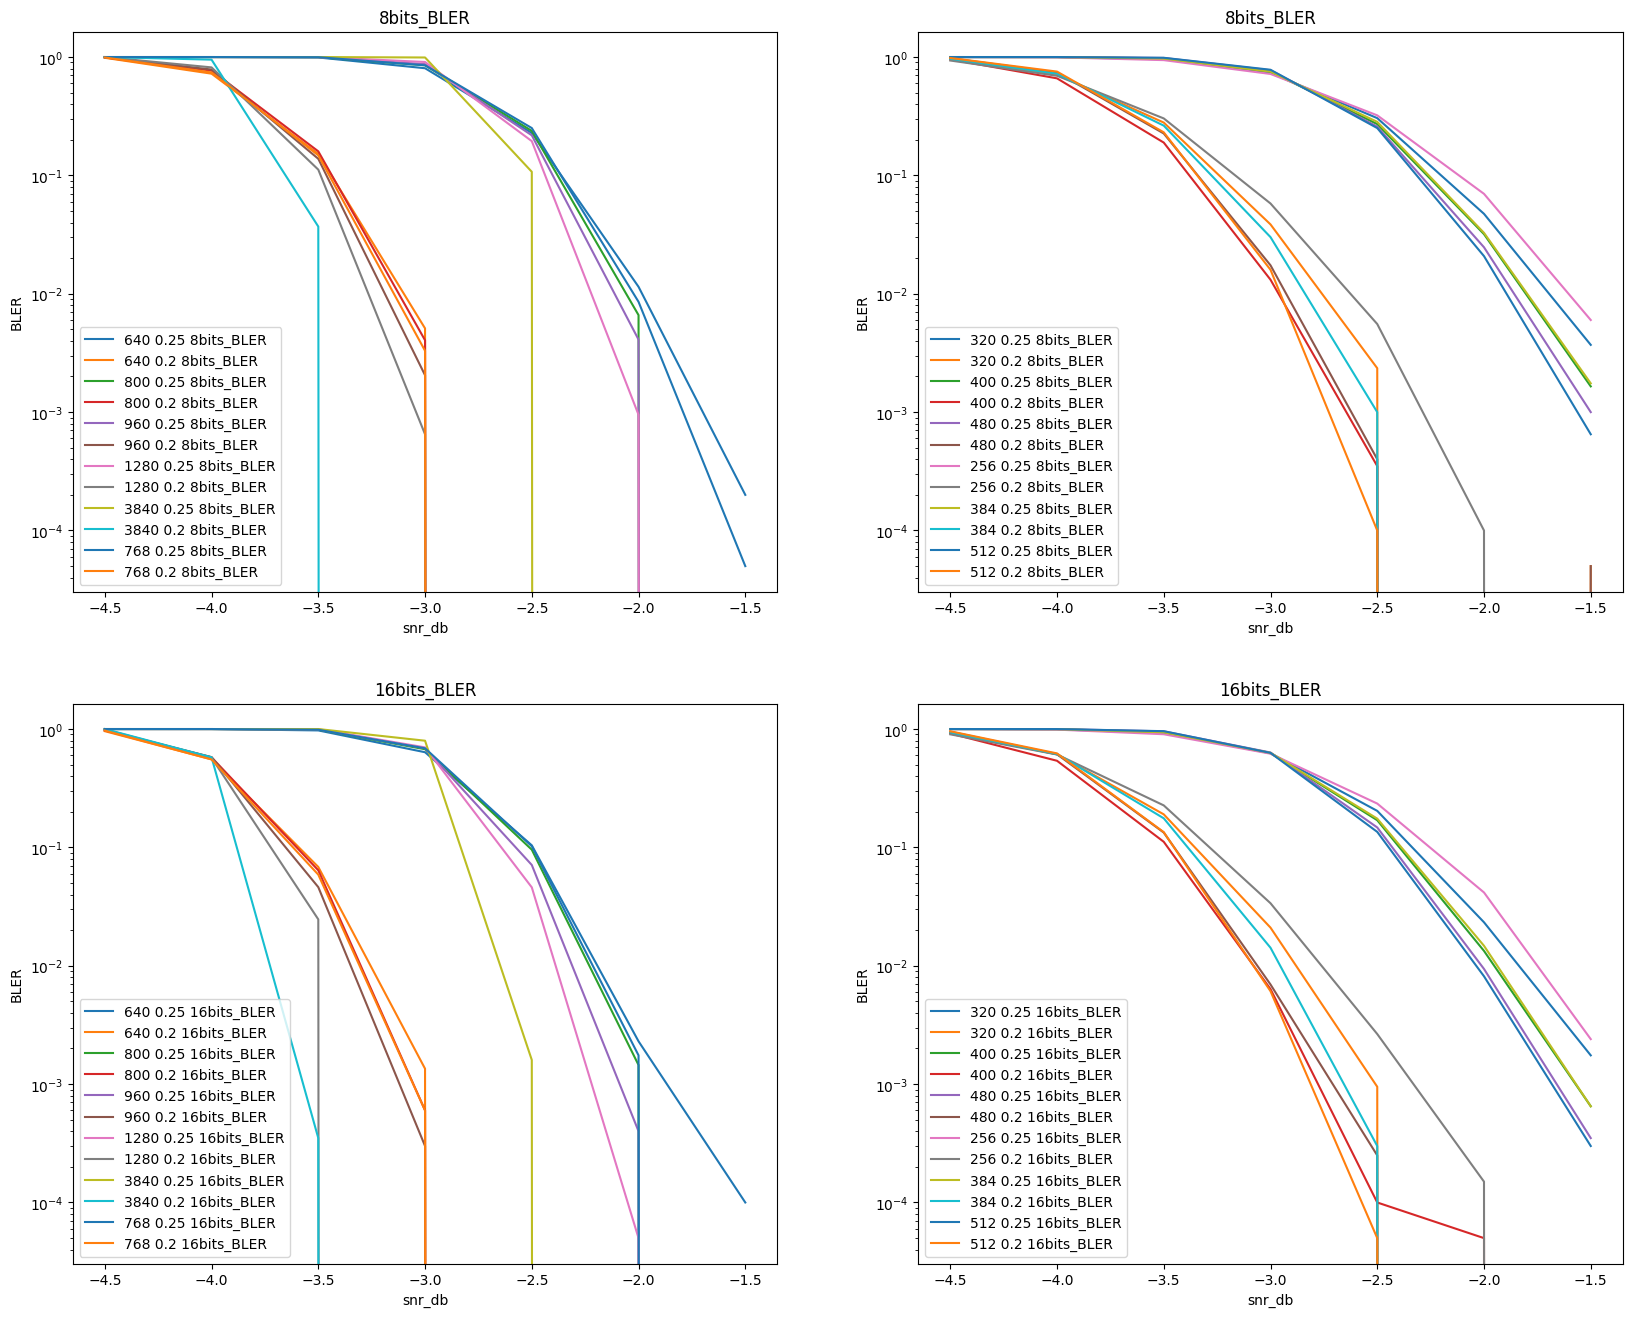

In [100]:
import matplotlib.pyplot as plt

#plot BLER
bler_col_list=['8bits_BLER','16bits_BLER']
ber_col_list=['8bits_BER','16bits_BER']

fig,axes = plt.subplots(2,2,figsize=(20,16))

bler_col = '8bits_BLER'
for idx,payload in enumerate(ber_df['payload'].unique()):
    sel_d = ber_df[ber_df['payload']==payload]
    for rate_idx, rate in enumerate(ber_df['rate'].unique()):
        if payload <=512:
            sel_ax = axes[0,1]
        else:
            sel_ax = axes[0,0]

        #for bler_col in bler_col_list:
        label = F"{payload} {rate} {bler_col}"
        sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y=bler_col,ax=sel_ax,label=label,errorbar=None)
axes[0,0].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[0,0].set_yscale('log') 
axes[0,0].legend()
        
axes[0,1].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[0,1].set_yscale('log') 
axes[0,1].legend()

bler_col = '16bits_BLER'
for idx,payload in enumerate(ber_df['payload'].unique()):
    sel_d = ber_df[ber_df['payload']==payload]
    for rate_idx, rate in enumerate(ber_df['rate'].unique()):
        if payload <=512:
            sel_ax = axes[1,1]
        else:
            sel_ax = axes[1,0]

        #for bler_col in bler_col_list:
        label = F"{payload} {rate} {bler_col}"
        sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y=bler_col,ax=sel_ax,label=label,errorbar=None)

axes[1,0].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[1,0].set_yscale('log') 
axes[1,0].legend()
        
axes[1,1].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[1,1].set_yscale('log') 
axes[1,1].legend()

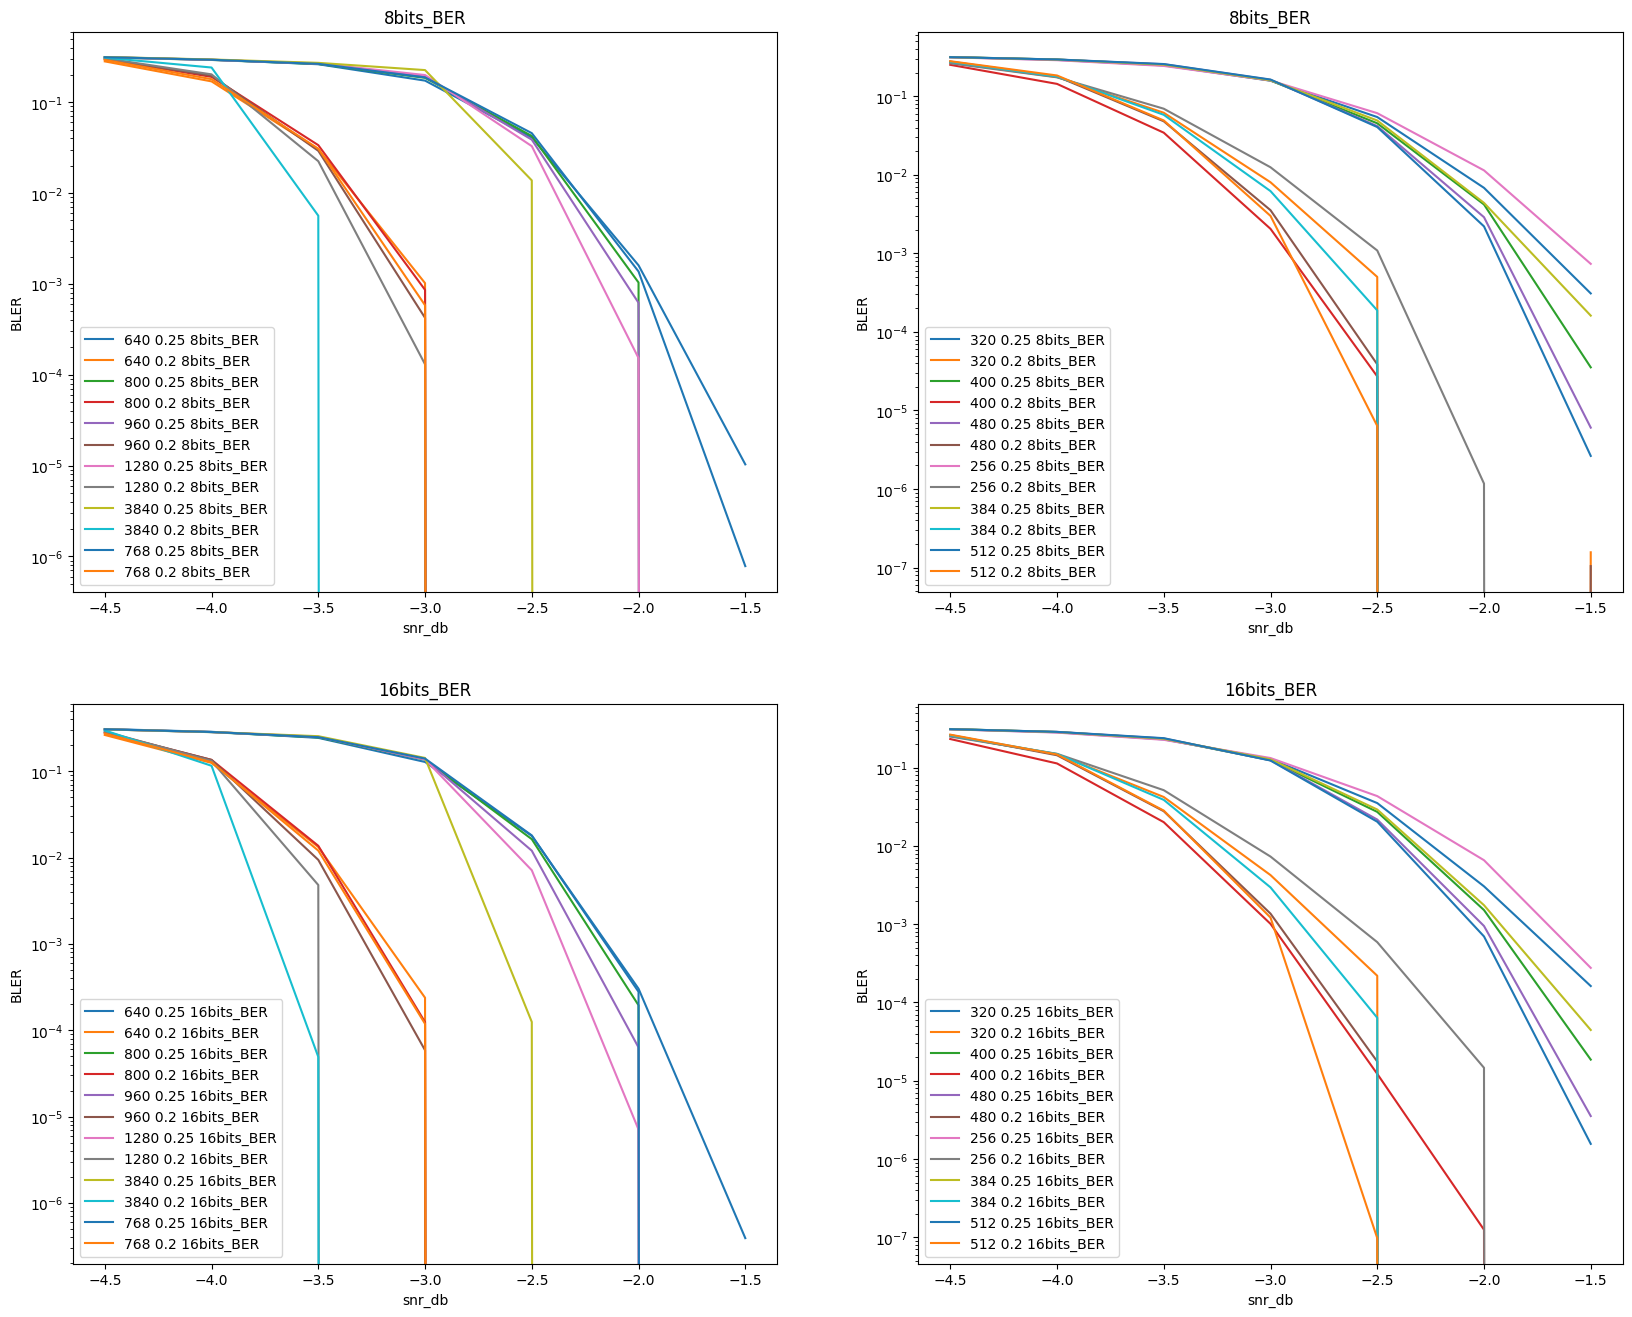

In [103]:
import matplotlib.pyplot as plt

#plot BLER
#bler_col_list=['8bits_BLER','16bits_BLER']
#ber_col_list=['8bits_BER','16bits_BER']

fig,axes = plt.subplots(2,2,figsize=(20,16))

bler_col = '8bits_BER'
for idx,payload in enumerate(ber_df['payload'].unique()):
    sel_d = ber_df[ber_df['payload']==payload]
    for rate_idx, rate in enumerate(ber_df['rate'].unique()):
        if payload <=512:
            sel_ax = axes[0,1]
        else:
            sel_ax = axes[0,0]

        #for bler_col in bler_col_list:
        label = F"{payload} {rate} {bler_col}"
        sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y=bler_col,ax=sel_ax,label=label,errorbar=None)
axes[0,0].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[0,0].set_yscale('log') 
axes[0,0].legend()
        
axes[0,1].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[0,1].set_yscale('log') 
axes[0,1].legend()

bler_col = '16bits_BER'
for idx,payload in enumerate(ber_df['payload'].unique()):
    sel_d = ber_df[ber_df['payload']==payload]
    for rate_idx, rate in enumerate(ber_df['rate'].unique()):
        if payload <=512:
            sel_ax = axes[1,1]
        else:
            sel_ax = axes[1,0]

        #for bler_col in bler_col_list:
        label = F"{payload} {rate} {bler_col}"
        sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y=bler_col,ax=sel_ax,label=label,errorbar=None)

axes[1,0].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[1,0].set_yscale('log') 
axes[1,0].legend()
        
axes[1,1].set(title=bler_col, xlabel='snr_db', ylabel='BLER')
axes[1,1].set_yscale('log') 
axes[1,1].legend()

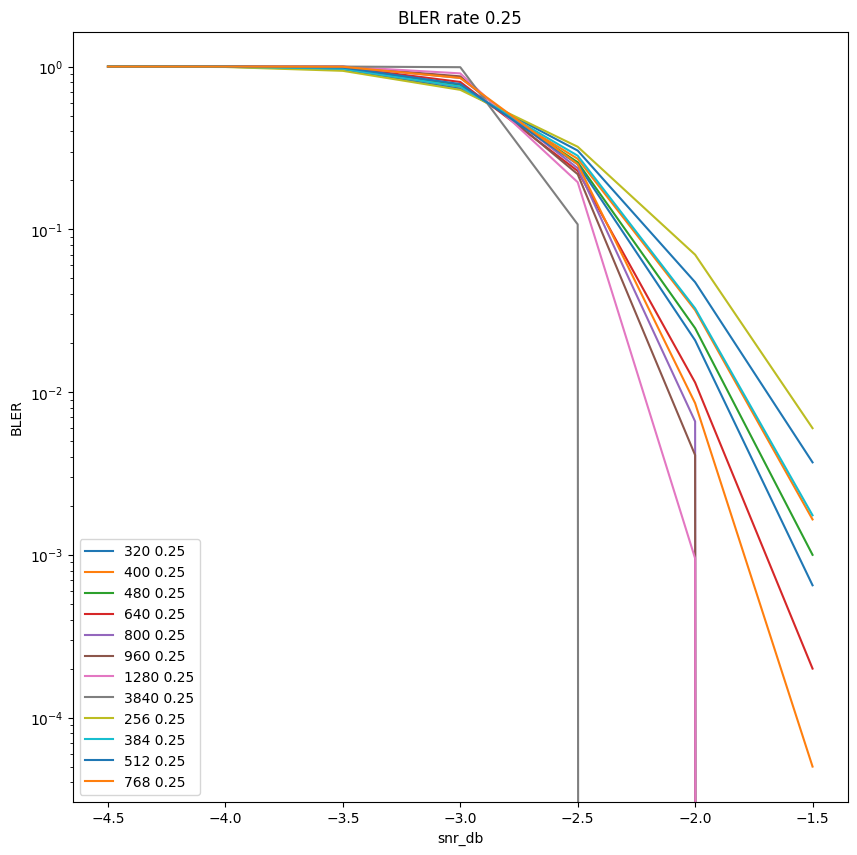

In [121]:
import matplotlib.pyplot as plt

bler_col_list=['8bits_BLER','16bits_BLER']
ber_col_list=['8bits_BER','16bits_BER']

#fig,axes = plt.subplots(1,2,figsize=(10,10))
#sns.lineplot(data=int16_df[int16_df['rate']==0.20][int16_df['payload'] <800], x='snr', y='f_BLER',hue='payload',errorbar=None,legend="full",palette="tab10",ax=axes[0])

fig,sel_ax = plt.subplots(figsize=(10,10))
for idx,payload in enumerate(ber_df['payload'].unique()):
    sel_d = ber_df[ber_df['payload']==payload]
    for rate_idx, rate in enumerate(ber_df['rate'].unique()):
        if rate == 0.25:
            label = F"{payload} {rate}"
            sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y='8bits_BLER',ax=sel_ax,label=label,errorbar=None)
sel_ax.set(title=f'BLER rate 0.25', xlabel='snr_db', ylabel='BLER')
sel_ax.set_yscale('log') 
sel_ax.legend()
        


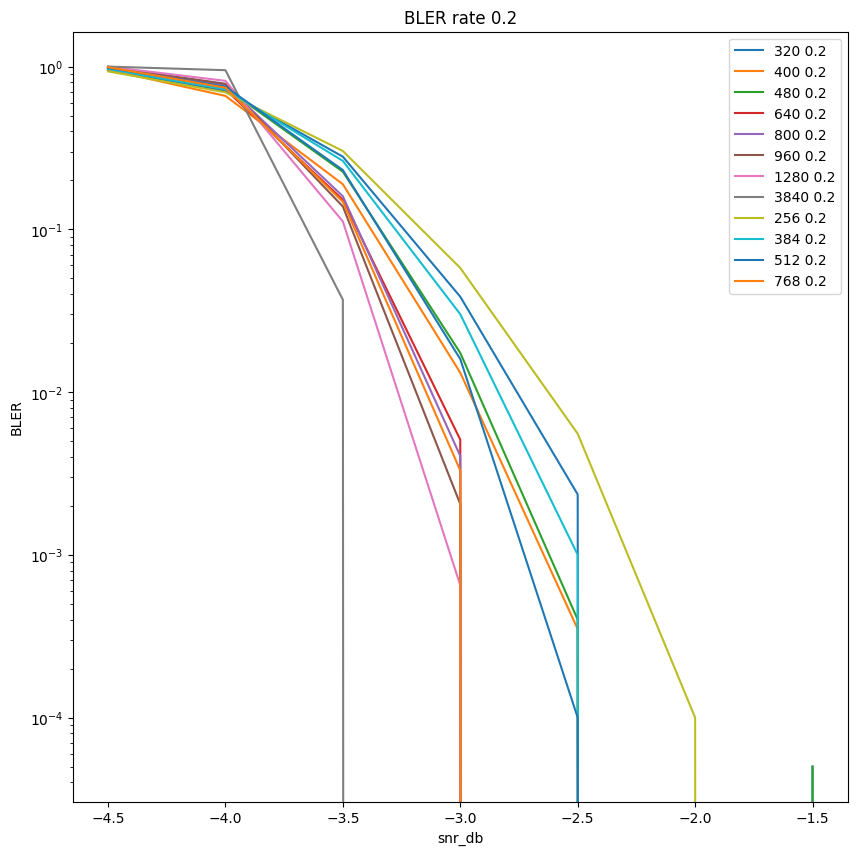

In [68]:
import matplotlib.pyplot as plt

bler_col_list=['8bits_BLER','16bits_BLER']
ber_col_list=['8bits_BER','16bits_BER']

fig,axes = plt.subplots(1,2,figsize=(10,10))
sns.lineplot(data=int16_df[int16_df['rate']==0.20][int16_df['payload'] <800], x='snr', y='f_BLER',hue='payload',errorbar=None,legend="full",palette="tab10",ax=axes[0])

for idx,payload in enumerate(ber_df['payload'].unique()):
    sel_d = ber_df[ber_df['payload']==payload]
    for rate_idx, rate in enumerate(ber_df['rate'].unique()):
        if rate == 0.2:
            label = F"{payload} {rate}"
            sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y='8bits_BLER',ax=sel_ax,label=label,errorbar=None)
sel_ax.set(title=f'BLER rate 0.2', xlabel='snr_db', ylabel='BLER')
sel_ax.set_yscale('log') 
sel_ax.legend()
        


## test 5: test different LDPC iteration size

**Summary of the test**
  - it tested 4 different LDPC iteration size[32, 24,16,8]
  - the test run both on int16 fixed point C code and 8bits fixed point C code
  - 20000 tests are accumulated for each test configuration (rate, payload size, snr, iteration)

**Observation of the test** 
- larger iteration size -> better performance
- small performance gap among Iteration size 16,24,32 : iteration 16 and iteration 24 are ~0.17 and ~0.08dB worse than iteration 32
- iteration size 8 is ~0.7dB worse than iteration 32

In [42]:
import importlib
importlib.reload(utils_for_plot)

L_df, L_df2 = utils_for_plot.process_int8_int16_L_fixed_point_simu_result()


In [44]:
bler_col_list = L_df.columns.tolist()[4:]
bler_col_list

['i8_L8',
 'i16_L8',
 'i8_L16',
 'i16_L16',
 'i8_L24',
 'i16_L24',
 'i8_L32',
 'i16_L32']

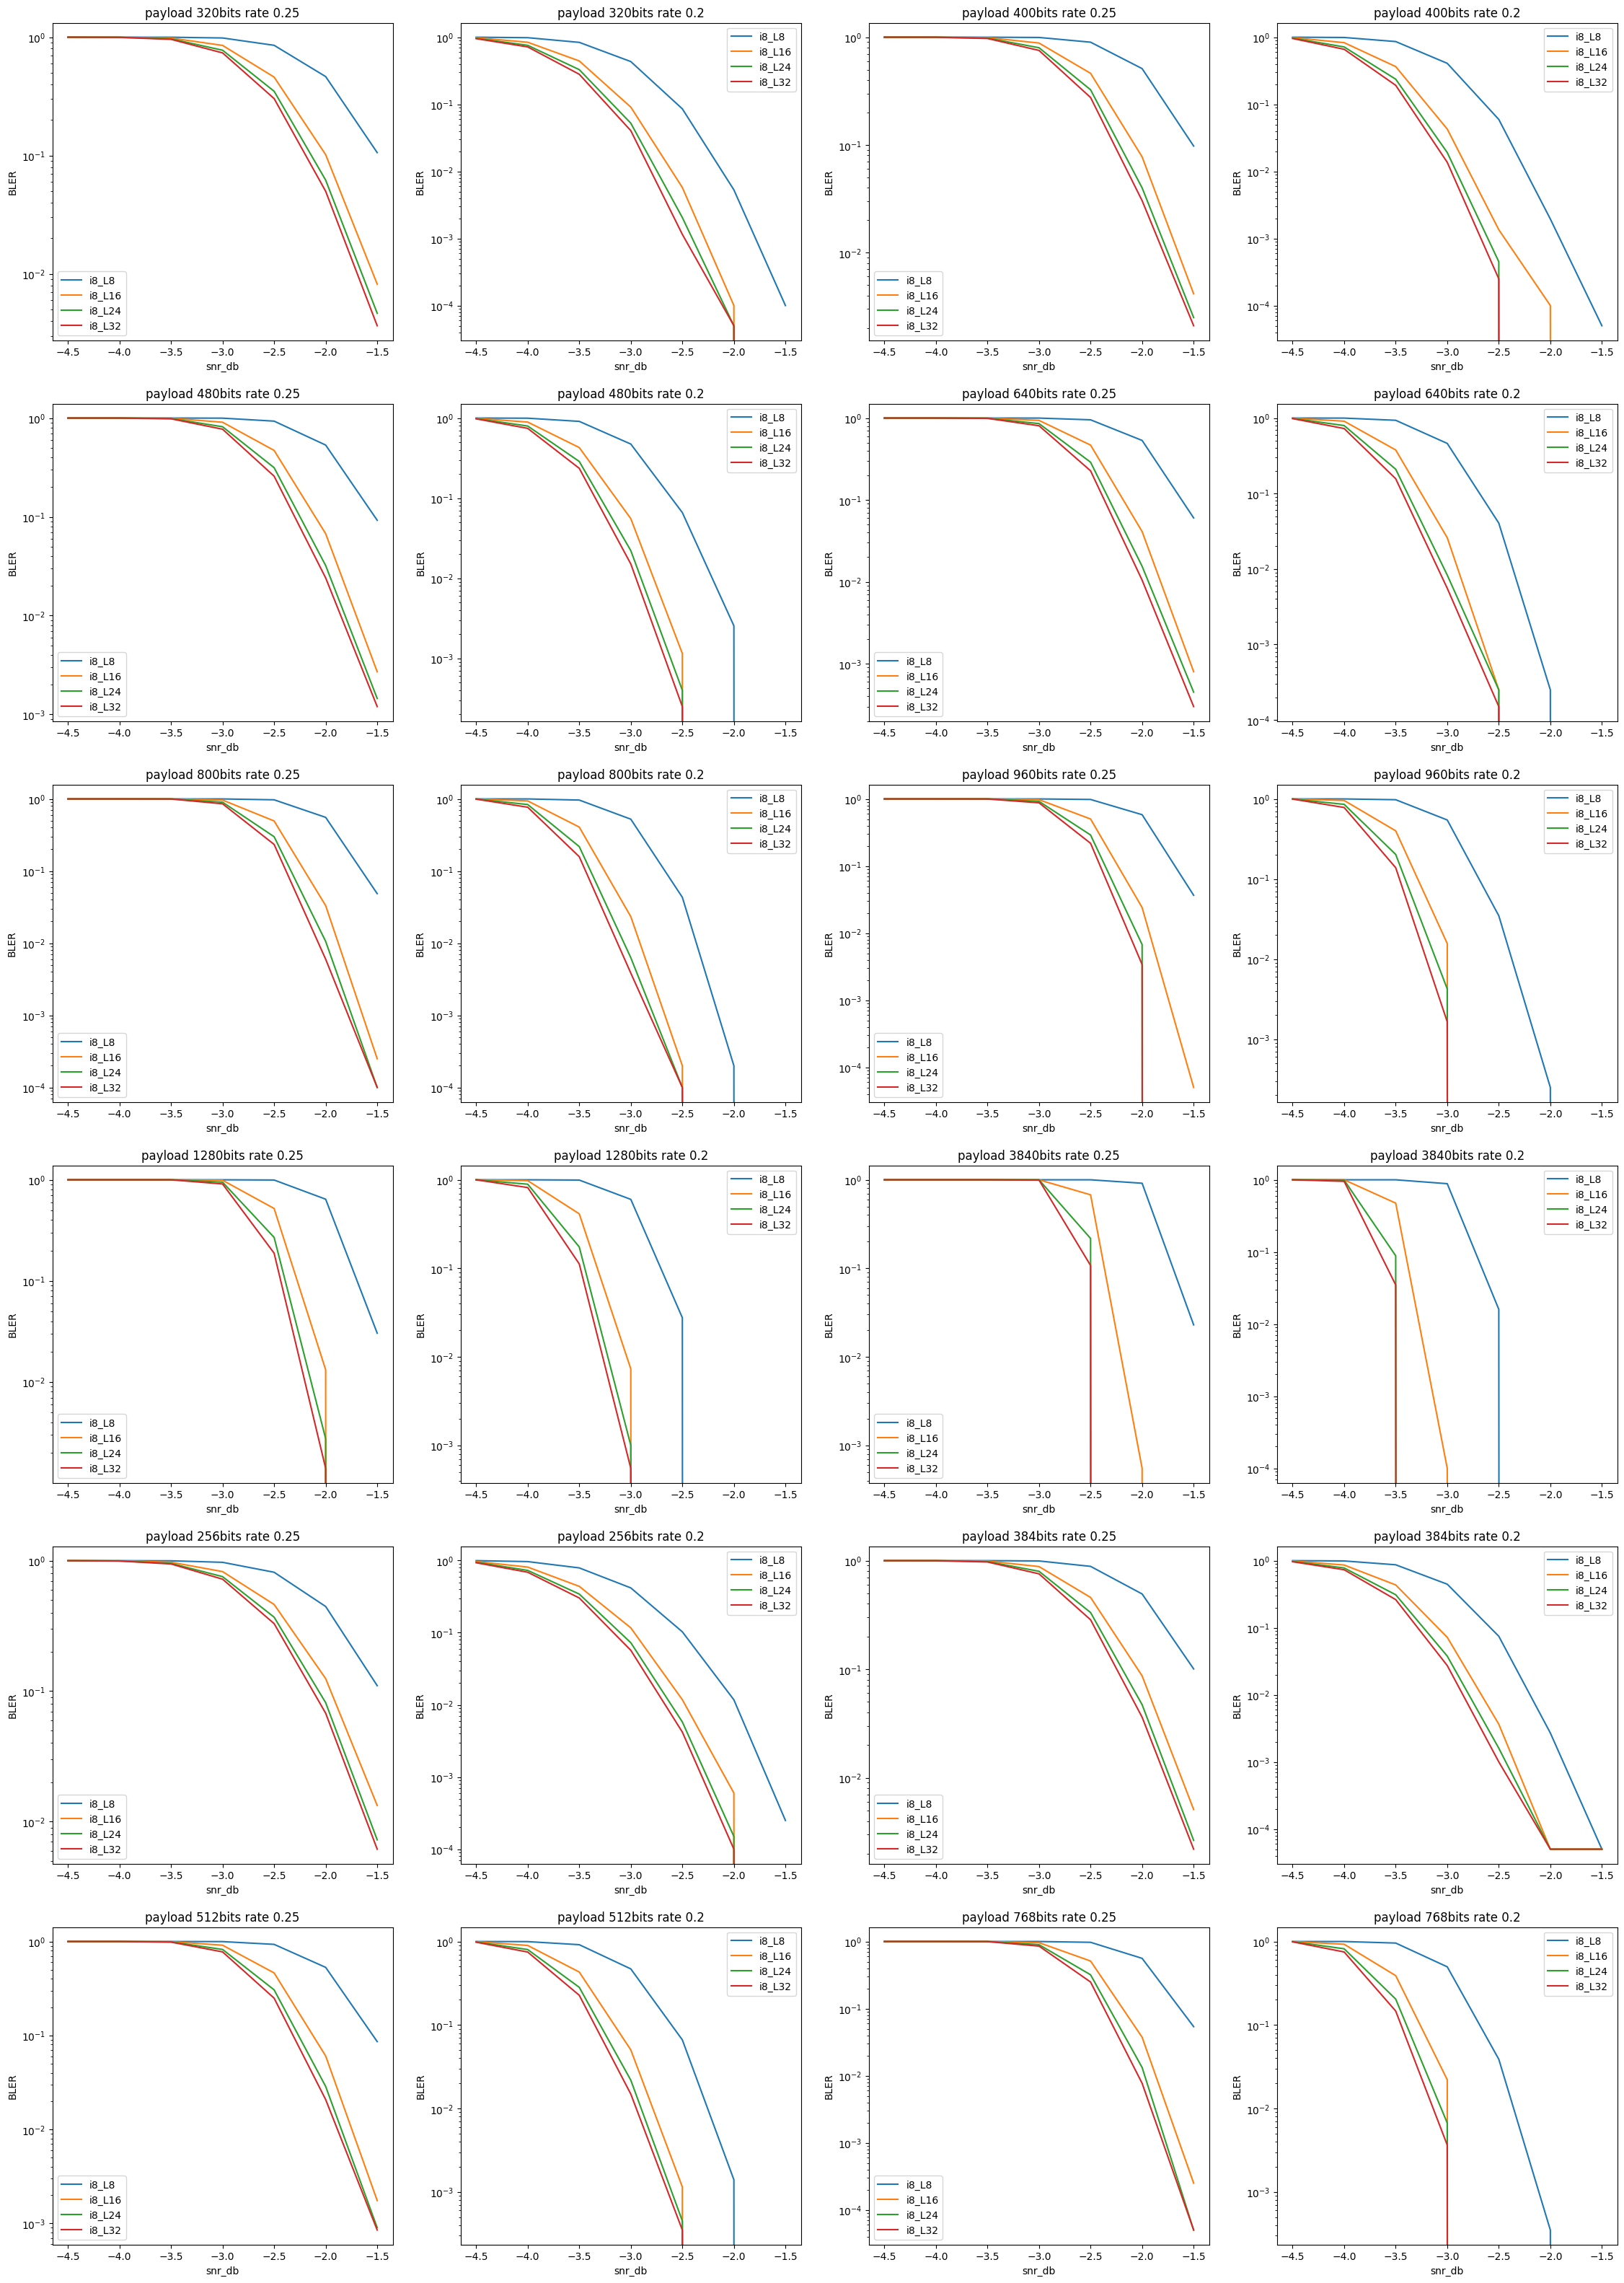

In [45]:
import matplotlib.pyplot as plt
#bler_col_list = L_df.columns.tolist()[4:]
bler_col_list=['i8_L8','i8_L16','i8_L24','i8_L32']

fig,axes = plt.subplots(6,4,figsize=(28,40))

for idx,payload in enumerate(L_df['payload'].unique()):
    sel_d = L_df[L_df['payload']==payload]
    for rate_idx, rate in enumerate(L_df['rate'].unique()):
        sel_ax = axes[idx //2, (idx % 2)*2+rate_idx]
        
        for label in bler_col_list:
            sns.lineplot(data=sel_d[sel_d['rate']==rate], x='snr', y=label,ax=sel_ax,label=label,errorbar=None)
            #print(f"{payload}, {rate},{label}")
            
        sel_ax.set(title=f'payload {payload}bits rate {rate}', xlabel='snr_db', ylabel='BLER')
        sel_ax.set_yscale('log') 
        sel_ax.legend()
    